## Module 5 – Assignment 11: NLP Model – Sentiment Analysis using LSTM.

### Project: Customer Review Sentiment Analysis using NLP and LSTM

### Task 1 – Text Data Preparation

### Import required libraries

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import re

import tensorflow as tf

from tensorflow.keras.datasets import imdb
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense, Dropout

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

print("TensorFlow Version:", tf.__version__)

TensorFlow Version: 2.22.0-rc1


### Load the IMDB dataset

In [3]:
vocab_size = 10000

(X_train, y_train), (X_test, y_test) = imdb.load_data(
    num_words=vocab_size
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

print("First review:", X_train[0][:20])
print("First sentiment:", y_train[0])

17464789/17464789 ━━━━━━━━━━━━━━━━━━━━ 6s 0us/step
Training samples: 25000
Testing samples: 25000
First review: [1, 14, 22, 16, 43, 530, 973, 1622, 1385, 65, 458, 4468, 66, 3941, 4, 173, 36, 256, 5, 25]
First sentiment: 1


### Decode numerical sequences into text

In [5]:
word_index = imdb.get_word_index()

reverse_word_index = {
    value: key for key, value in word_index.items()
}

def decode_review(sequence):
    return " ".join(
        reverse_word_index.get(i - 3, "?")
        for i in sequence
        if i >= 3
    )

sample_review = decode_review(X_train[0])

print(sample_review)

1641221/1641221 ━━━━━━━━━━━━━━━━━━━━ 1s 1us/step
this film was just brilliant casting location scenery story direction everyone's really suited the part they played and you could just imagine being there robert is an amazing actor and now the same being director father came from the same scottish island as myself so i loved the fact there was a real connection with this film the witty remarks throughout the film were great it was just brilliant so much that i bought the film as soon as it was released for and would recommend it to everyone to watch and the fly fishing was amazing really cried at the end it was so sad and you know what they say if you cry at a film it must have been good and this definitely was also to the two little boy's that played the of norman and paul they were just brilliant children are often left out of the list i think because the stars that play them all grown up are such a big profile for the whole film but these children are amazing and should be praised fo

### Text cleaning

In [6]:
def clean_text(text):

    text = text.lower()

    text = re.sub(r"<br\s*/?>", " ", text)

    text = re.sub(r"[^a-z\s]", " ", text)

    text = re.sub(r"\s+", " ", text).strip()

    return text

cleaned_review = clean_text(sample_review)

print("Original Review:")
print(sample_review[:300])

print("\nCleaned Review:")
print(cleaned_review[:300])

Original Review:
this film was just brilliant casting location scenery story direction everyone's really suited the part they played and you could just imagine being there robert is an amazing actor and now the same being director father came from the same scottish island as myself so i loved the fact there was a re

Cleaned Review:
this film was just brilliant casting location scenery story direction everyone s really suited the part they played and you could just imagine being there robert is an amazing actor and now the same being director father came from the same scottish island as myself so i loved the fact there was a re


### Tokenization and stopword removal

In [8]:
import nltk

from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize

nltk.download("punkt")
nltk.download("punkt_tab")
nltk.download("stopwords")

stop_words = set(stopwords.words("english"))

def preprocess_text(text):

    words = word_tokenize(text)

    words = [
        word for word in words
        if word not in stop_words
    ]

    return words

tokens = preprocess_text(cleaned_review)

print("Tokens:")
print(tokens[:30])

[nltk_data] Downloading package punkt to C:\Users\Varshini
[nltk_data]     D\AppData\Roaming\nltk_data...
[nltk_data]   Unzipping tokenizers\punkt.zip.
[nltk_data] Downloading package punkt_tab to C:\Users\Varshini
[nltk_data]     D\AppData\Roaming\nltk_data...
[nltk_data]   Unzipping tokenizers\punkt_tab.zip.
[nltk_data] Downloading package punkt_tab to C:\Users\Varshini
[nltk_data]     D\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package stopwords to C:\Users\Varshini
[nltk_data]     D\AppData\Roaming\nltk_data...


Tokens:
['film', 'brilliant', 'casting', 'location', 'scenery', 'story', 'direction', 'everyone', 'really', 'suited', 'part', 'played', 'could', 'imagine', 'robert', 'amazing', 'actor', 'director', 'father', 'came', 'scottish', 'island', 'loved', 'fact', 'real', 'connection', 'film', 'witty', 'remarks', 'throughout']


[nltk_data]   Unzipping corpora\stopwords.zip.


### Stemming (optional)

In [9]:
from nltk.stem import PorterStemmer

stemmer = PorterStemmer()

stemmed_words = [
    stemmer.stem(word)
    for word in tokens
]

print("Original words:")
print(tokens[:15])

print("\nStemmed words:")
print(stemmed_words[:15])

Original words:
['film', 'brilliant', 'casting', 'location', 'scenery', 'story', 'direction', 'everyone', 'really', 'suited', 'part', 'played', 'could', 'imagine', 'robert']

Stemmed words:
['film', 'brilliant', 'cast', 'locat', 'sceneri', 'stori', 'direct', 'everyon', 'realli', 'suit', 'part', 'play', 'could', 'imagin', 'robert']


### Word indexing and sequence generation

In [10]:
print("Original sequence:")
print(X_train[0][:20])

print("\nSequence length:")
print(len(X_train[0]))

Original sequence:
[1, 14, 22, 16, 43, 530, 973, 1622, 1385, 65, 458, 4468, 66, 3941, 4, 173, 36, 256, 5, 25]

Sequence length:
218


### Padding sequences

In [11]:
max_length = 200

X_train_padded = pad_sequences(
    X_train,
    maxlen=max_length,
    padding="post",
    truncating="post"
)

X_test_padded = pad_sequences(
    X_test,
    maxlen=max_length,
    padding="post",
    truncating="post"
)

print("Training shape:", X_train_padded.shape)
print("Testing shape:", X_test_padded.shape)

Training shape: (25000, 200)
Testing shape: (25000, 200)


### Train-validation splitting

In [12]:
X_train_final, X_val, y_train_final, y_val = train_test_split(
    X_train_padded,
    y_train,
    test_size=0.2,
    random_state=42,
    stratify=y_train
)

print("Training:", X_train_final.shape)
print("Validation:", X_val.shape)
print("Testing:", X_test_padded.shape)

Training: (20000, 200)
Validation: (5000, 200)
Testing: (25000, 200)


### Task 2 – Text Representation

In [13]:
train_texts = [decode_review(seq) for seq in X_train]
test_texts = [decode_review(seq) for seq in X_test]

train_texts = [clean_text(text) for text in train_texts]
test_texts = [clean_text(text) for text in test_texts]

print(train_texts[0][:300])

this film was just brilliant casting location scenery story direction everyone s really suited the part they played and you could just imagine being there robert is an amazing actor and now the same being director father came from the same scottish island as myself so i loved the fact there was a re


### Bag of Words representation

In [14]:
bow_vectorizer = CountVectorizer(
    max_features=10000
)

X_train_bow = bow_vectorizer.fit_transform(train_texts)

X_test_bow = bow_vectorizer.transform(test_texts)

print("Training BoW shape:", X_train_bow.shape)
print("Testing BoW shape:", X_test_bow.shape)

Training BoW shape: (25000, 9622)
Testing BoW shape: (25000, 9622)


In [15]:
bow_features = bow_vectorizer.get_feature_names_out()

bow_df = pd.DataFrame(
    X_train_bow[:5].toarray(),
    columns=bow_features
)

print(bow_df.iloc[:, :15])

   aaron  abandon  abandoned  abc  abilities  ability  able  aboard  \
0      0        0          0    0          0        0     0       0   
1      0        0          0    0          0        0     0       0   
2      0        0          0    0          0        0     0       0   
3      0        0          0    0          0        0     0       0   
4      0        0          0    0          0        0     0       0   

   abomination  abortion  abound  about  above  abraham  abroad  
0            0         0       0      0      0        0       0  
1            1         0       0      0      0        0       0  
2            0         0       0      0      0        0       0  
3            0         0       0      1      0        0       0  
4            0         0       0      0      0        0       0  


### TF-IDF representation

In [16]:
tfidf_vectorizer = TfidfVectorizer(
    max_features=10000
)

X_train_tfidf = tfidf_vectorizer.fit_transform(train_texts)

X_test_tfidf = tfidf_vectorizer.transform(test_texts)

print("Training TF-IDF shape:", X_train_tfidf.shape)
print("Testing TF-IDF shape:", X_test_tfidf.shape)

Training TF-IDF shape: (25000, 9622)
Testing TF-IDF shape: (25000, 9622)


In [17]:
tfidf_features = tfidf_vectorizer.get_feature_names_out()

tfidf_df = pd.DataFrame(
    X_train_tfidf[:5].toarray(),
    columns=tfidf_features
)

print(tfidf_df.iloc[:, :15])

   aaron  abandon  abandoned  abc  abilities  ability  able  aboard  \
0    0.0      0.0        0.0  0.0        0.0      0.0   0.0     0.0   
1    0.0      0.0        0.0  0.0        0.0      0.0   0.0     0.0   
2    0.0      0.0        0.0  0.0        0.0      0.0   0.0     0.0   
3    0.0      0.0        0.0  0.0        0.0      0.0   0.0     0.0   
4    0.0      0.0        0.0  0.0        0.0      0.0   0.0     0.0   

   abomination  abortion  abound     about  above  abraham  abroad  
0     0.000000       0.0     0.0  0.000000    0.0      0.0     0.0  
1     0.127257       0.0     0.0  0.000000    0.0      0.0     0.0  
2     0.000000       0.0     0.0  0.000000    0.0      0.0     0.0  
3     0.000000       0.0     0.0  0.015477    0.0      0.0     0.0  
4     0.000000       0.0     0.0  0.000000    0.0      0.0     0.0  


### Word Embedding representation

In [18]:
embedding_dim = 128

embedding_layer = Embedding(
    input_dim=vocab_size,
    output_dim=embedding_dim,
    input_length=max_length
)

sample_input = tf.constant(X_train_padded[:2])

sample_embedding = embedding_layer(sample_input)

print("Input shape:", sample_input.shape)
print("Embedding shape:", sample_embedding.shape)

Input shape: (2, 200)
Embedding shape: (2, 200, 128)


c:\Users\Varshini D\Desktop\M-5 Assignment-11\.myvenv\Lib\site-packages\keras\src\layers\core\embedding.py:104: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


### Compare the three techniques

In [19]:
comparison = pd.DataFrame({
    "Technique": [
        "Bag of Words",
        "TF-IDF",
        "Word Embedding"
    ],
    "Representation": [
        "Word frequency",
        "Word importance",
        "Dense word vectors"
    ],
    "Main Advantage": [
        "Simple and easy",
        "Highlights informative words",
        "Learns semantic relationships"
    ],
    "Limitation": [
        "Ignores word order",
        "Ignores word order",
        "Requires training or pretrained vectors"
    ]
})

print(comparison)

        Technique      Representation                 Main Advantage  \
0    Bag of Words      Word frequency                Simple and easy   
1          TF-IDF     Word importance   Highlights informative words   
2  Word Embedding  Dense word vectors  Learns semantic relationships   

                                Limitation  
0                       Ignores word order  
1                       Ignores word order  
2  Requires training or pretrained vectors  


### Task 3 – LSTM Model Development

### Build the LSTM model

In [20]:
model = Sequential([

    Embedding(
        input_dim=vocab_size,
        output_dim=128,
        input_length=max_length
    ),

    LSTM(
        units=64
    ),

    Dropout(0.5),

    Dense(
        units=1,
        activation="sigmoid"
    )
])

model.summary()

c:\Users\Varshini D\Desktop\M-5 Assignment-11\.myvenv\Lib\site-packages\keras\src\layers\core\embedding.py:104: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_1 (Embedding)         │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

### Compile the model

In [21]:
model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

print("Model compiled successfully!")

Model compiled successfully!


### Train the model

In [22]:
history = model.fit(
    X_train_final,
    y_train_final,
    epochs=5,
    batch_size=64,
    validation_data=(X_val, y_val),
    verbose=1
)

Epoch 1/5
313/313 ━━━━━━━━━━━━━━━━━━━━ 31s 96ms/step - accuracy: 0.5540 - loss: 0.6815 - val_accuracy: 0.5526 - val_loss: 0.6836
Epoch 2/5
313/313 ━━━━━━━━━━━━━━━━━━━━ 26s 84ms/step - accuracy: 0.5875 - loss: 0.6681 - val_accuracy: 0.5266 - val_loss: 0.6985
Epoch 3/5
313/313 ━━━━━━━━━━━━━━━━━━━━ 22s 71ms/step - accuracy: 0.5958 - loss: 0.6539 - val_accuracy: 0.6816 - val_loss: 0.6072
Epoch 4/5
313/313 ━━━━━━━━━━━━━━━━━━━━ 22s 71ms/step - accuracy: 0.5592 - loss: 0.6839 - val_accuracy: 0.5798 - val_loss: 0.6645
Epoch 5/5
313/313 ━━━━━━━━━━━━━━━━━━━━ 22s 71ms/step - accuracy: 0.5992 - loss: 0.6440 - val_accuracy: 0.5900 - val_loss: 0.6587


### Generate predictions

In [23]:
y_probability = model.predict(X_test_padded)

y_pred = (y_probability >= 0.5).astype(int).flatten()

print("Actual sentiments:")
print(y_test[:10])

print("\nPredicted sentiments:")
print(y_pred[:10])

782/782 ━━━━━━━━━━━━━━━━━━━━ 12s 15ms/step
Actual sentiments:
[0 1 1 0 1 1 1 0 0 1]

Predicted sentiments:
[1 1 1 1 1 1 0 1 1 1]


### Create a sentiment prediction function

In [24]:
def predict_sentiment(review):

    words = re.findall(r"[a-z]+", review.lower())

    sequence = []

    for word in words:

        index = word_index.get(word)

        if index is None or index + 3 >= vocab_size:
            sequence.append(2)
        else:
            sequence.append(index + 3)

    padded_sequence = pad_sequences(
        [sequence],
        maxlen=max_length,
        padding="post",
        truncating="post"
    )

    probability = model.predict(
        padded_sequence,
        verbose=0
    )[0][0]

    sentiment = "Positive" if probability >= 0.5 else "Negative"

    print("Review:", review)
    print("Sentiment:", sentiment)
    print("Positive probability:", round(float(probability), 4))

    return sentiment

### Test the model:

In [25]:
predict_sentiment(
    "This movie was amazing and I really enjoyed it"
)

predict_sentiment(
    "This movie was boring and very disappointing"
)

Review: This movie was amazing and I really enjoyed it
Sentiment: Positive
Positive probability: 0.5084
Review: This movie was boring and very disappointing
Sentiment: Positive
Positive probability: 0.5084


'Positive'

### Note: The prediction function uses the IMDB vocabulary mapping, including its reserved token offsets. It is a simple inference demonstration; real-world reviews may contain words outside the training vocabulary.

### Task 4 – Model Evaluation

### Calculate evaluation metrics

In [26]:
accuracy = accuracy_score(y_test, y_pred)

precision = precision_score(y_test, y_pred)

recall = recall_score(y_test, y_pred)

f1 = f1_score(y_test, y_pred)

print("Model Evaluation Results")
print("------------------------")

print("Accuracy :", round(accuracy, 4))
print("Precision:", round(precision, 4))
print("Recall   :", round(recall, 4))
print("F1 Score :", round(f1, 4))

Model Evaluation Results
------------------------
Accuracy : 0.5866
Precision: 0.5628
Recall   : 0.776
F1 Score : 0.6524


### Classification report

In [27]:
print(
    classification_report(
        y_test,
        y_pred,
        target_names=["Negative", "Positive"]
    )
)

              precision    recall  f1-score   support

    Negative       0.64      0.40      0.49     12500
    Positive       0.56      0.78      0.65     12500

    accuracy                           0.59     25000
   macro avg       0.60      0.59      0.57     25000
weighted avg       0.60      0.59      0.57     25000



### Confusion Matrix

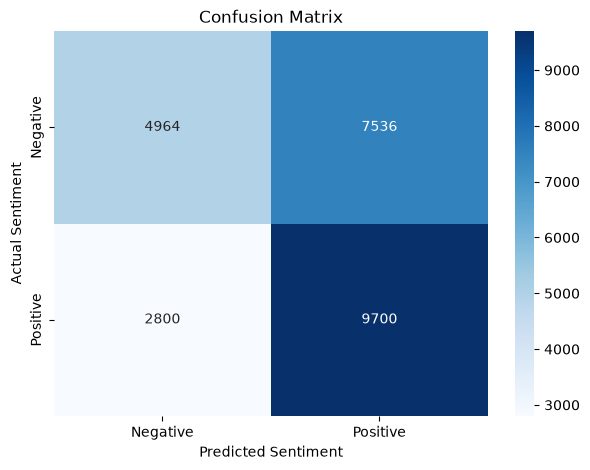

In [28]:
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Negative", "Positive"],
    yticklabels=["Negative", "Positive"]
)

plt.xlabel("Predicted Sentiment")
plt.ylabel("Actual Sentiment")
plt.title("Confusion Matrix")

plt.show()

### Training vs Validation Accuracy

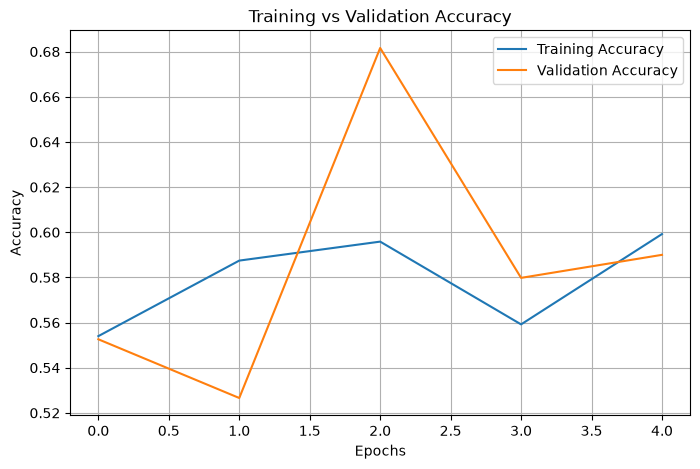

In [29]:
plt.figure(figsize=(8, 5))

plt.plot(
    history.history["accuracy"],
    label="Training Accuracy"
)

plt.plot(
    history.history["val_accuracy"],
    label="Validation Accuracy"
)

plt.title("Training vs Validation Accuracy")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")

plt.legend()
plt.grid()

plt.show()

### Training vs Validation Loss

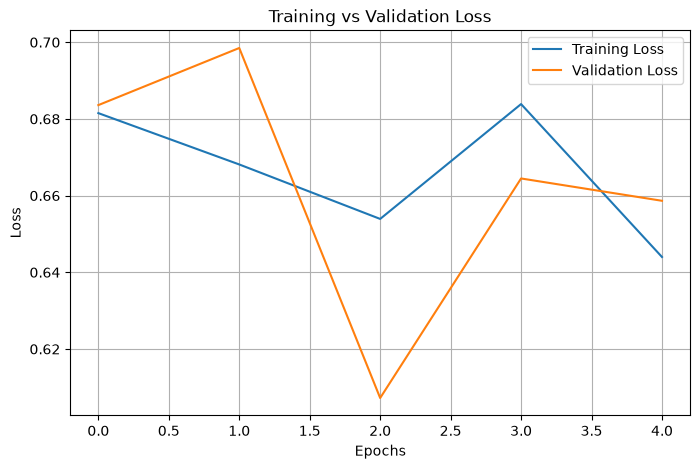

In [30]:
plt.figure(figsize=(8, 5))

plt.plot(
    history.history["loss"],
    label="Training Loss"
)

plt.plot(
    history.history["val_loss"],
    label="Validation Loss"
)

plt.title("Training vs Validation Loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")

plt.legend()
plt.grid()

plt.show()

### Actual vs Predicted Sentiment Comparison

In [31]:
comparison_df = pd.DataFrame({
    "Actual": y_test[:20],
    "Predicted": y_pred[:20]
})

comparison_df["Actual"] = comparison_df["Actual"].map({
    0: "Negative",
    1: "Positive"
})

comparison_df["Predicted"] = comparison_df["Predicted"].map({
    0: "Negative",
    1: "Positive"
})

print(comparison_df)

      Actual Predicted
0   Negative  Positive
1   Positive  Positive
2   Positive  Positive
3   Negative  Positive
4   Positive  Positive
5   Positive  Positive
6   Positive  Negative
7   Negative  Positive
8   Negative  Positive
9   Positive  Positive
10  Positive  Positive
11  Negative  Negative
12  Negative  Positive
13  Negative  Positive
14  Positive  Positive
15  Negative  Negative
16  Positive  Positive
17  Negative  Positive
18  Negative  Negative
19  Negative  Positive


### Visualize the comparison:

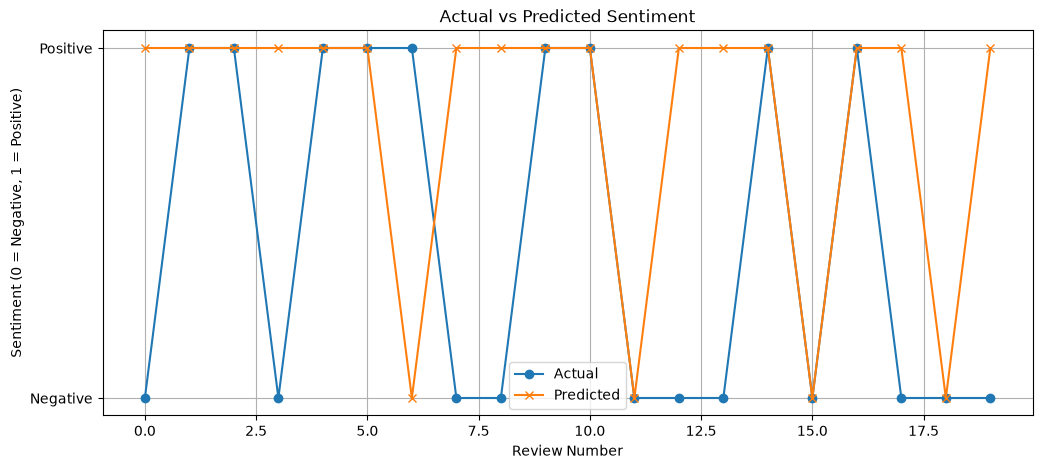

In [32]:
plt.figure(figsize=(12, 5))

x = np.arange(20)

plt.plot(
    x,
    y_test[:20],
    marker="o",
    label="Actual"
)

plt.plot(
    x,
    y_pred[:20],
    marker="x",
    label="Predicted"
)

plt.xlabel("Review Number")
plt.ylabel("Sentiment (0 = Negative, 1 = Positive)")

plt.title("Actual vs Predicted Sentiment")

plt.yticks([0, 1], ["Negative", "Positive"])

plt.legend()
plt.grid()

plt.show()

### Save the trained model

In [33]:
model.save("imdb_sentiment_lstm.keras")

print("Model saved successfully!")

Model saved successfully!


### Task 5 – Performance Analysis

### Impact of Sequence Length

In [34]:
sequence_lengths = [100, 200, 300]

for length in sequence_lengths:

    X_temp = pad_sequences(
        X_train,
        maxlen=length,
        padding="post",
        truncating="post"
    )

    print(
        f"Sequence length: {length}, Shape: {X_temp.shape}"
    )

Sequence length: 100, Shape: (25000, 100)
Sequence length: 200, Shape: (25000, 200)
Sequence length: 300, Shape: (25000, 300)


### Importance of Embedding Layer

In [35]:
embedding_layer = Embedding(
    input_dim=10000,
    output_dim=128,
    input_length=200
)

print("Embedding vocabulary size:", 10000)
print("Embedding dimensions:", 128)

Embedding vocabulary size: 10000
Embedding dimensions: 128


c:\Users\Varshini D\Desktop\M-5 Assignment-11\.myvenv\Lib\site-packages\keras\src\layers\core\embedding.py:104: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


### Analysis:
- Embedding converts word indexes into dense numerical vectors.

- Similar words can learn similar vector representations.

- It reduces the limitations of sparse representations.

- It helps the LSTM understand patterns in textual data.

### 5.3 Effect of LSTM Memory Cells

### Analysis:
- LSTM stands for Long Short-Term Memory.
 
- It uses memory cells to retain useful information. 

- It uses input, forget and output gates.

- It helps learn dependencies between words in a sequence.

- It reduces the vanishing gradient problem compared with basic RNNs.

### 5.4 Overfitting and Possible Solutions

### Analysis:

Overfitting happens when the model performs well on training data but poorly on unseen data.

Possible solutions:

1. Dropout regularization.

2. Early stopping.

3. Reducing model complexity.

4. Increasing training data.

5. Hyperparameter tuning.

### Limitations of the Model

### Analysis:

1. The model may struggle with sarcasm.

2. It may misunderstand complex sentences.

3. It has limitations with unknown words.

4. Training requires computational resources.

5. It may not generalize well to domains other than movie reviews.

6. It does not always understand the deeper context of language.